# Flux: figures of the hot summer 2026 for a general audience

# About this notebook

This notebook draws four figures on the hot summer of 2026 at CH-LAE for readers outside the field, for example in a newspaper. They show the main results of [`FLUX_NEE_IRGA72_HOT_SUMMER_2026`](FLUX_NEE_IRGA72_HOT_SUMMER_2026.ipynb) in plain language and compute nothing that notebook does not. Each figure is saved as PNG (300 dpi) and PDF to `workflow/90_OVERVIEW/figures/`.

**Translations used in the figures**

- Net CO2 uptake is `-NEE` (`NEE_L3.1_L3.3_CUT_50_QCF_gfXG`), summed per day and converted from gC m⁻² to tonnes of CO2 per hectare (1 gC m⁻² = 0.0366 t CO2 ha⁻¹). The uncertainty stated for 2026 is the range of the USTAR scenarios `CUT_16` and `CUT_84`.
- Photosynthesis is `GPP_NT_OF_CUT_50`, respiration `RECO_NT_OF_CUT_50` (nighttime partitioning).
- The share of the sun's energy used to evaporate water is the midday evaporative fraction `LE / (LE + H)` from measured half-hours between 11:00 and 15:00 CET; strictly it is the share of the turbulent energy flux, not of the incoming radiation.
- Air temperature is the homogenised, gap-filled `TA` at 47 m. The heat-wave periods marked in figure 4 (18-30 June and 27 July-16 August) are read from the 7-day running mean of the daily maximum.

**Design.** Orange marks 2026 and blue the 2016-2025 average throughout; grey shows the range of 2016-2025. The two colours are slots 1 and 2 of a categorical palette checked for colour-vision deficiency (adjacent separation ΔE 24.7) and for at least 3:1 contrast on the background.

</br>

# Settings

In [1]:
from pathlib import Path

DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
FILE_NEE72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet"
FILE_LE72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\25_FPPC_IRGA72_LE_2016-2026.09.parquet"
FILE_H72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\35_FPPC_IRGA72_H_2016-2026.09.parquet"
FILE_METEO = r"10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet"
OUTDIR = Path('figures')  # relative to this notebook: workflow/90_OVERVIEW/figures

MONTHS = [6, 7, 8, 9]
YEAR = 2026
REF_YEARS = list(range(2016, 2026))

NEE = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'
NEE_LO, NEE_HI = 'NEE_L3.1_L3.3_CUT_16_QCF_gfXG', 'NEE_L3.1_L3.3_CUT_84_QCF_gfXG'
GPP, RECO = 'GPP_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50'
LE, LE_FLAG = 'LE_L3.1_L3.3_CUT_NONE_QCF_gfXG', 'FLAG_LE_L3.1_L3.3_CUT_NONE_QCF_gfXG_ISFILLED'
H, H_FLAG = 'H_L3.1_L3.3_CUT_NONE_QCF_gfXG', 'FLAG_H_L3.1_L3.3_CUT_NONE_QCF_gfXG_ISFILLED'
TA = 'TA_T1_47_1_HOMOGENIZED_gfXG'
MIDDAY = (11, 15)
HOT_DAY = 30.0

# umol CO₂ m-2 s-1 over one half-hour -> gC m-2 -> tonnes CO₂ per hectare
GC = 12.011e-6 * 1800
T_CO2_HA = 10 * 44.01 / 12.011 / 1000  # 1 gC m-2 = 10 kg C ha-1 = 0.0366 t CO₂ ha-1

# Design tokens. Blue and orange are slots 1 and 2 of the validated reference palette of the
# dataviz guidance (adjacent CVD separation 24.7, normal-vision 33.6, both above 3:1 contrast).
SURFACE = '#fcfcfb'
INK, INK_2, INK_3 = '#1d1d1b', '#52514e', '#8a8984'
GRID = '#e6e4df'
C_YEAR = '#eb6834'   # 2026
C_NORM = '#2a78d6'   # average of 2016-2025
C_BAND = '#e9e7e2'   # range of 2016-2025
C_OTHER = '#c9c6bf'  # single other years
FONT = 'Segoe UI'
SOURCE = "Data: CH-LAE eddy-covariance flux tower, Lägern forest (Switzerland), 2016-2026"

# Imports

In [2]:
import calendar
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

warnings.filterwarnings('ignore', category=RuntimeWarning)

# Style and helpers

In [3]:
mpl.rcParams.update({
    'font.family': FONT, 'font.size': 10, 'text.color': INK,
    'axes.facecolor': SURFACE, 'figure.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.linewidth': 1,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5,
    'xtick.major.size': 0, 'ytick.major.size': 0, 'xtick.major.pad': 6, 'ytick.major.pad': 6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'lines.solid_capstyle': 'round', 'lines.solid_joinstyle': 'round',
    'svg.fonttype': 'none', 'pdf.fonttype': 42,
})

W = 8.0  # figure width in inches; about two newspaper columns at 300 dpi


def frame(height, top=1.35, bottom=0.55, nrows=1, ncols=1, hspace=0.45, wspace=0.18, sharex=False, sharey=False,
          right=0.955):
    """A figure with room for a headline block above and a source line below the plot area."""
    fig = plt.figure(figsize=(W, height))
    gs = fig.add_gridspec(nrows, ncols, left=0.085, right=right, top=1 - top / height,
                          bottom=bottom / height, hspace=hspace, wspace=wspace)
    axes = gs.subplots(sharex=sharex, sharey=sharey)
    return fig, np.atleast_1d(axes)


def headline(fig, title, subtitle, height):
    """Headline and standfirst at the top left, in the newspaper manner."""
    fig.text(0.035, 1 - 0.30 / height, title, fontsize=16.5, fontweight='bold', color=INK, va='top')
    fig.text(0.035, 1 - 0.72 / height, subtitle, fontsize=10.5, color=INK_2, va='top', linespacing=1.4)


def footer(fig, note=None):
    """Source line, and an optional note above it, at the bottom left."""
    fig.text(0.035, 0.018, SOURCE, fontsize=8, color=INK_3, va='bottom')
    if note:
        fig.text(0.035, 0.018 + 0.03 * 8 / fig.get_size_inches()[1] * 1.0 + 0.012, note,
                 fontsize=8, color=INK_3, va='bottom', linespacing=1.4)


def key(fig, x, y, items):
    """A one-row legend of short line or block keys, placed in figure coordinates."""
    for kind, color, label in items:
        if kind == 'line':
            fig.add_artist(plt.Line2D([x, x + 0.03], [y, y], color=color, lw=2.6, solid_capstyle='round',
                                      transform=fig.transFigure))
        else:
            fig.add_artist(Rectangle((x, y - 0.012), 0.03, 0.024, color=color, transform=fig.transFigure, lw=0))
        t = fig.text(x + 0.038, y, label, fontsize=9.5, color=INK_2, va='center')
        fig.canvas.draw()
        bb = t.get_window_extent().transformed(fig.transFigure.inverted())
        x = bb.x1 + 0.03


def rbar(ax, x, h, width, color, r_px=4):
    """A bar with a rounded data end and a square end at the zero baseline. Call after the limits are set."""
    if h == 0 or np.isnan(h):
        return
    fig = ax.figure
    fig.canvas.draw()
    px = ax.transData.transform([(0, 0), (1, 1)])
    ppx, ppy = abs(px[1, 0] - px[0, 0]), abs(px[1, 1] - px[0, 1])
    rx = r_px * fig.dpi / 100 / ppx
    ry = r_px * fig.dpi / 100 / ppy
    r_eff = min(rx, width / 2)
    ax.add_patch(FancyBboxPatch((x - width / 2, min(0, h)), width, abs(h),
                                boxstyle=f"round,pad=0,rounding_size={r_eff}",
                                mutation_aspect=ry / rx, color=color, lw=0, zorder=3))
    sq = min(abs(h), max(abs(h) - ry, abs(h) / 2))
    ax.add_patch(Rectangle((x - width / 2, 0 if h > 0 else -sq), width, sq, color=color, lw=0, zorder=3))


def season_day(index):
    """Days since 1 June of the same year."""
    return (index - pd.DatetimeIndex(pd.to_datetime([f"{y}-06-01" for y in index.year]))).days


def date_axis(ax):
    ticks = [0, 30, 61, 92, 121]
    ax.set_xticks(ticks, ['1 June', '1 July', '1 August', '1 September', '30 September'])
    ax.set_xlim(-1, 123)


def save(fig, name):
    OUTDIR.mkdir(exist_ok=True)
    for ext in ('png', 'pdf'):
        fig.savefig(OUTDIR / f"{name}.{ext}", dpi=300)

# Load data

In [4]:
_files = [DATADIR / f for f in (FILE_NEE72, FILE_LE72, FILE_H72, FILE_METEO)]
_missing = [str(p) for p in _files if not p.exists()]
if _missing:
    raise FileNotFoundError("The flux and meteo products in the external data folder are not available "
                            "here. Missing:\n  " + "\n  ".join(_missing))
df = (pd.read_parquet(_files[0], columns=[NEE, NEE_LO, NEE_HI, GPP, RECO])
      .join(pd.read_parquet(_files[1], columns=[LE, LE_FLAG]))
      .join(pd.read_parquet(_files[2], columns=[H, H_FLAG]))
      .join(pd.read_parquet(_files[3], columns=[TA])))
s = df[df.index.month.isin(MONTHS)].copy()
s['year'] = s.index.year
assert sorted(s['year'].unique()) == REF_YEARS + [YEAR] and (s.groupby('year').size() == 122 * 48).all()
assert s[[NEE, NEE_LO, NEE_HI, GPP, RECO, TA]].notna().all().all()
print(f"{len(s):,} half-hours, June-September {REF_YEARS[0]}-{YEAR}")

64,416 half-hours, June-September 2016-2026


</br>

# Figures

## 📊 Plot: days of 30 °C or more per summer

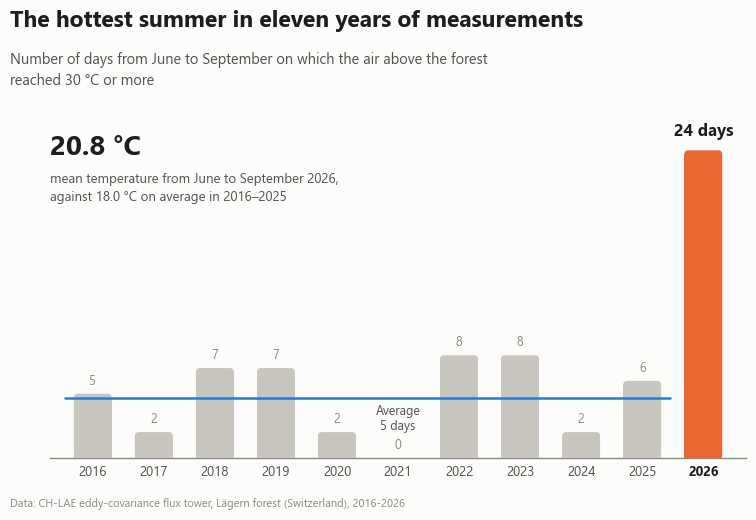

In [5]:
_tmax = s[TA].resample('D').max().dropna()
_tmax = _tmax[_tmax.index.month.isin(MONTHS)]
hot_days = _tmax.ge(HOT_DAY).groupby(_tmax.index.year).sum()
mean_ta = s.groupby('year')[TA].mean()

H1 = 5.4
fig, (ax,) = frame(H1, top=1.45, bottom=0.62)
years = hot_days.index.to_numpy()
ax.set_xlim(years[0] - 0.7, years[-1] + 0.7)
ax.set_ylim(0, 26)
ax.set_yticks([0, 5, 10, 15, 20, 25])
for y, v in hot_days.items():
    rbar(ax, y, v, 0.62, C_YEAR if y == YEAR else C_OTHER)
ref_mean = hot_days.loc[REF_YEARS].mean()
ax.plot([years[0] - 0.45, REF_YEARS[-1] + 0.45], [ref_mean] * 2, color=C_NORM, lw=1.8, zorder=4)
ax.text(2021, ref_mean - 0.6, f"Average\n{ref_mean:.0f} days", ha='center', va='top',
        color=INK_2, fontsize=9, linespacing=1.2)
ax.text(YEAR, hot_days[YEAR] + 0.8, f"{hot_days[YEAR]:.0f} days", ha='center', va='bottom',
        fontsize=12, fontweight='bold', color=INK)
for y, v in hot_days.items():
    if y != YEAR:
        ax.text(y, v + 0.5, f"{v:.0f}", ha='center', va='bottom', fontsize=9, color=INK_3)
ax.set_xticks(years, [str(y) for y in years])
ax.tick_params(axis='x', colors=INK_2)
ax.get_xticklabels()[-1].set_fontweight('bold')
ax.get_xticklabels()[-1].set_color(INK)
ax.grid(False)
ax.set_yticks([])
ax.spines['bottom'].set_color(INK_3)
ax.text(0.0, 0.97, f"{mean_ta[YEAR]:.1f} °C", transform=ax.transAxes, fontsize=20, fontweight='bold',
        color=INK, va='top')
ax.text(0.0, 0.855, f"mean temperature from June to September {YEAR},\n"
        f"against {mean_ta.loc[REF_YEARS].mean():.1f} °C on average in {REF_YEARS[0]}–{REF_YEARS[-1]}",
        transform=ax.transAxes, fontsize=9.5, color=INK_2, va='top', linespacing=1.45)
headline(fig, f"The hottest summer in eleven years of measurements",
         f"Number of days from June to September on which the air above the forest\n"
         f"reached 30 °C or more", H1)
footer(fig)
save(fig, 'HOT_SUMMER_2026_1_hot_days')
plt.show()

## 📊 Plot: cumulative net CO2 uptake from June to September

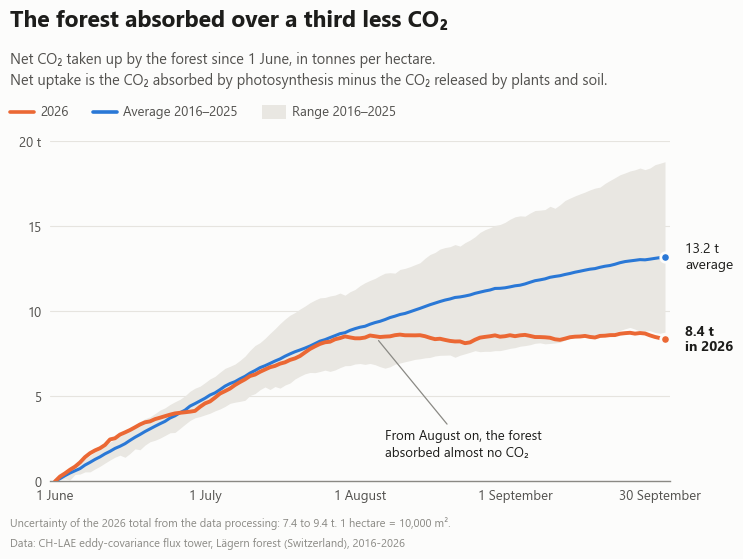

In [6]:
# Daily totals, so the lines show the course of the season without the day-night cycle.
_up = (-(s[NEE]) * GC * T_CO2_HA).resample('D').sum()
_up = _up[_up.index.month.isin(MONTHS)]
_cum = _up.groupby(_up.index.year).cumsum()
wide = pd.DataFrame({y: np.r_[0, _cum[_cum.index.year == y].to_numpy()] for y in REF_YEARS + [YEAR]},
                    index=np.arange(0, 123))
lo = (-(s.loc[s['year'] == YEAR, NEE_LO]) * GC * T_CO2_HA).cumsum().iloc[-1]
hi = (-(s.loc[s['year'] == YEAR, NEE_HI]) * GC * T_CO2_HA).cumsum().iloc[-1]
avg = wide[REF_YEARS].mean(axis=1)

H2 = 5.8
fig, (ax,) = frame(H2, top=1.62, bottom=0.78, right=0.86)
ax.fill_between(wide.index, wide[REF_YEARS].min(axis=1), wide[REF_YEARS].max(axis=1), color=C_BAND, lw=0, zorder=1)
ax.plot(wide.index, avg, color=C_NORM, lw=2.2, zorder=3)
ax.plot(wide.index, wide[YEAR], color=C_YEAR, lw=2.8, zorder=4)
for col, color in ((avg, C_NORM), (wide[YEAR], C_YEAR)):
    ax.scatter([wide.index[-1]], [col.iloc[-1]], s=46, color=color, edgecolor=SURFACE, linewidth=2, zorder=5)
ax.text(126, avg.iloc[-1], f"{avg.iloc[-1]:.1f} t\naverage", va='center', fontsize=10, color=INK, linespacing=1.25)
ax.text(126, wide[YEAR].iloc[-1], f"{wide[YEAR].iloc[-1]:.1f} t\nin {YEAR}", va='center', fontsize=10,
        color=INK, fontweight='bold', linespacing=1.25)
_x = 64
ax.annotate("From August on, the forest\nabsorbed almost no CO₂",
            xy=(_x, wide[YEAR].loc[wide.index >= _x].iloc[0]), xytext=(66, 2.2),
            fontsize=9.5, color=INK, linespacing=1.4, va='center',
            arrowprops=dict(arrowstyle='-', color=INK_3, lw=0.9, shrinkA=2, shrinkB=4))
date_axis(ax)
ax.set_ylim(0, 20)
ax.set_yticks([0, 5, 10, 15, 20], ['0', '5', '10', '15', '20 t'])
ax.spines['bottom'].set_color(INK_3)
headline(fig, "The forest absorbed over a third less CO₂",
         "Net CO₂ taken up by the forest since 1 June, in tonnes per hectare.\n"
         "Net uptake is the CO₂ absorbed by photosynthesis minus the CO₂ released by plants and soil.", H2)
key(fig, 0.035, 1 - 1.33 / H2, [('line', C_YEAR, str(YEAR)), ('line', C_NORM, f'Average {REF_YEARS[0]}–{REF_YEARS[-1]}'),
                               ('block', C_BAND, f'Range {REF_YEARS[0]}–{REF_YEARS[-1]}')])
fig.text(0.035, 0.018 + 0.2 / H2, f"Uncertainty of the {YEAR} total from the data processing: {min(lo, hi):.1f} to {max(lo, hi):.1f} t. "
         f"1 hectare = 10,000 m².", fontsize=8, color=INK_3, va='bottom')
footer(fig)
save(fig, 'HOT_SUMMER_2026_2_co2_uptake')
plt.show()

## 📊 Plot: monthly change of photosynthesis and respiration in 2026

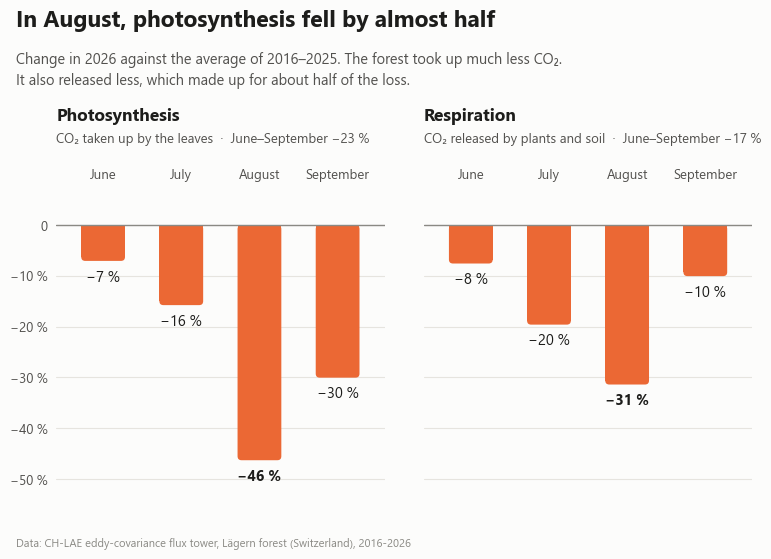

In [7]:
_m = s.groupby(['year', s.index.month])[[GPP, RECO]].sum() * GC
_ref = _m.loc[REF_YEARS].groupby(level=1).mean()
pct = (_m.loc[YEAR] / _ref - 1) * 100
_tot = s.groupby('year')[[GPP, RECO]].sum() * GC
pct_season = (_tot.loc[YEAR] / _tot.loc[REF_YEARS].mean() - 1) * 100

H3 = 5.8
fig, axes = frame(H3, top=2.05, bottom=0.55, ncols=2, wspace=0.12, sharey=True)
names = {GPP: ("Photosynthesis", "CO₂ taken up by the leaves"),
         RECO: ("Respiration", "CO₂ released by plants and soil")}
for ax, col in zip(axes, (GPP, RECO)):
    ax.set_xlim(-0.6, 3.6)
    ax.set_ylim(-55, 8)
    for i, m in enumerate(MONTHS):
        rbar(ax, i, pct.loc[m, col], 0.56, C_YEAR)
        ax.text(i, pct.loc[m, col] - 1.6, f"{pct.loc[m, col]:.0f} %".replace('-', '−'), ha='center', va='top',
                fontsize=10.5, fontweight='bold' if m == 8 else 'normal', color=INK)
    ax.axhline(0, color=INK_3, lw=1, zorder=4)
    ax.set_xticks(range(4), [calendar.month_name[m] for m in MONTHS])
    ax.tick_params(axis='x', pad=2)
    ax.xaxis.tick_top()
    ax.set_yticks([-50, -40, -30, -20, -10, 0])
    ax.set_yticklabels(['−50 %', '−40 %', '−30 %', '−20 %', '−10 %', '0'])
    ax.spines['bottom'].set_visible(False)
    t, sub = names[col]
    ax.text(0.0, 1.20, t, transform=ax.transAxes, fontsize=12.5, fontweight='bold', color=INK)
    ax.text(0.0, 1.13, f"{sub}  ·  June–September {pct_season[col]:.0f} %".replace('-', '−'),
            transform=ax.transAxes, fontsize=9.5, color=INK_2)
axes[1].tick_params(axis='y', labelleft=False)
headline(fig, "In August, photosynthesis fell by almost half",
         f"Change in {YEAR} against the average of {REF_YEARS[0]}–{REF_YEARS[-1]}. The forest took up much less CO₂.\n"
         f"It also released less, which made up for about half of the loss.", H3)
footer(fig)
save(fig, 'HOT_SUMMER_2026_3_photosynthesis_respiration')
plt.show()

## 📊 Plot: daily maximum temperature and evaporative fraction

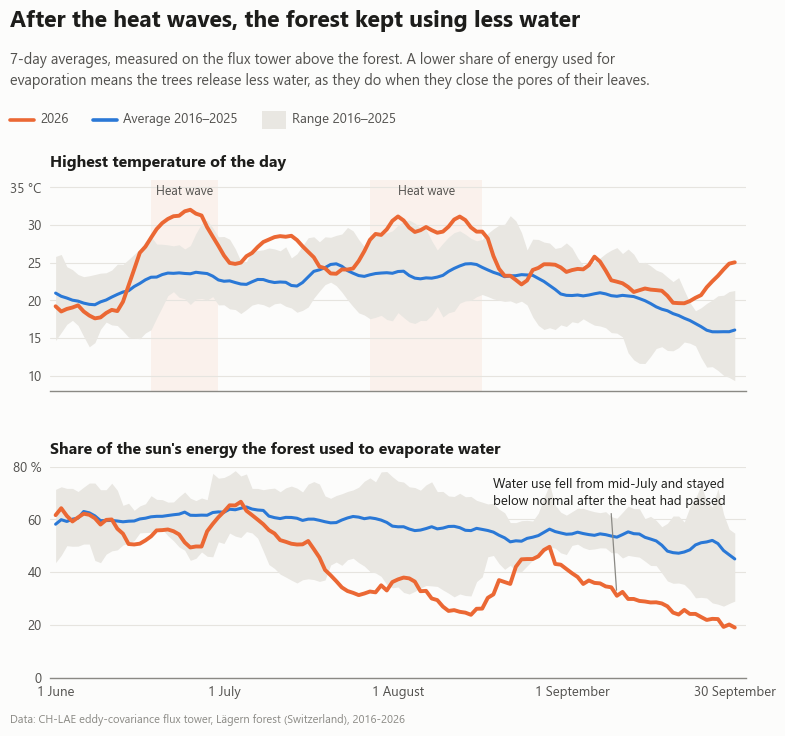

In [8]:
_d = pd.DataFrame({'tmax': s[TA].resample('D').max()})
_mid = s[(s.index.hour >= MIDDAY[0]) & (s.index.hour < MIDDAY[1]) & s[LE_FLAG].eq(0) & s[H_FLAG].eq(0)]
_mid = _mid[(_mid[LE] + _mid[H]) > 50]
_e = _mid[[LE, H]].resample('D').agg(['sum', 'count'])
_d['ef'] = (100 * _e[(LE, 'sum')] / (_e[(LE, 'sum')] + _e[(H, 'sum')])).where(_e[(LE, 'count')] >= 4)
_d = _d[_d.index.month.isin(MONTHS)]
_d['year'] = _d.index.year
_d['day'] = season_day(_d.index)

H4 = 7.6
fig, axes = frame(H4, top=2.0, bottom=0.62, nrows=2, hspace=0.36, sharex=True)
panels = (('tmax', "Highest temperature of the day", "°C", (8, 36), [10, 15, 20, 25, 30, 35]),
          ('ef', "Share of the sun's energy the forest used to evaporate water", "%", (0, 80), [0, 20, 40, 60, 80]))
for ax, (col, title, unit, ylim, ticks) in zip(axes, panels):
    w = _d.pivot(index='day', columns='year', values=col).rolling(7, center=True, min_periods=3).mean()
    ax.fill_between(w.index, w[REF_YEARS].min(axis=1), w[REF_YEARS].max(axis=1), color=C_BAND, lw=0, zorder=1)
    ax.plot(w.index, w[REF_YEARS].mean(axis=1), color=C_NORM, lw=2.2, zorder=3)
    ax.plot(w.index, w[YEAR], color=C_YEAR, lw=2.8, zorder=4)
    ax.set_ylim(*ylim)
    ax.set_yticks(ticks, [f"{t}" if t != ticks[-1] else f"{t} {unit}" for t in ticks])
    ax.text(0.0, 1.06, title, transform=ax.transAxes, fontsize=11.5, fontweight='bold', color=INK)
    ax.spines['bottom'].set_color(INK_3)
    if col == 'tmax':
        for x0, x1, lab in ((17, 29, "Heat wave"), (56, 76, "Heat wave")):
            ax.axvspan(x0, x1, color=C_YEAR, alpha=0.07, lw=0, zorder=0)
            ax.text((x0 + x1) / 2, 35.3, lab, ha='center', va='top', fontsize=9, color=INK_2)
    else:
        ax.annotate("Water use fell from mid-July and stayed\nbelow normal after the heat had passed",
                    xy=(100, w[YEAR].loc[100]), xytext=(78, 70), fontsize=9.5, color=INK, linespacing=1.4,
                    va='center', arrowprops=dict(arrowstyle='-', color=INK_3, lw=0.9, shrinkA=2, shrinkB=4))
date_axis(axes[-1])
headline(fig, "After the heat waves, the forest kept using less water",
         "7-day averages, measured on the flux tower above the forest. A lower share of energy used for\n"
         "evaporation means the trees release less water, as they do when they close the pores of their leaves.", H4)
key(fig, 0.035, 1 - 1.40 / H4, [('line', C_YEAR, str(YEAR)), ('line', C_NORM, f'Average {REF_YEARS[0]}–{REF_YEARS[-1]}'),
                               ('block', C_BAND, f'Range {REF_YEARS[0]}–{REF_YEARS[-1]}')])
footer(fig)
save(fig, 'HOT_SUMMER_2026_4_heat_and_water')
plt.show()

</br>

# End of notebook